# 03. Comparação de classificadores e treino do modelo oficial

**Universidade Presbiteriana Mackenzie** · Tecnologia em Banco de Dados · Projeto Aplicado II  
**Grupo Drop Table:** Igor Eduardo Dallan do Couto (RA 10748144), Jaqueline de Oliveira Alves (RA 10755023), Kayo Oliveira Nukui (RA 10356420) e Lucas de Lima Mendes (RA 10756562)  
**Empresa fictícia:** ConectaShop  
**Responsável por este notebook:** Jaqueline de Oliveira Alves

Queremos um modelo que leia o comentário e diga se ele é negativo, neutro ou positivo. Este notebook compara quatro algoritmos usando só o conjunto de treino, mostra como a Regressão Logística, que é o modelo oficial do projeto, se sai diante das alternativas e treina esse modelo com `src/treinamento.py`.

**Entrada:** `data/processed/treino.csv` (e `teste.csv`, usado apenas pelo script de treino para salvar as previsões)
**Saídas (em `data/processed/modelo/`):** `modelo_sentimento.joblib`, `metricas_modelo.json` e `previsoes_teste.csv`

O conjunto de teste não é usado para escolher o modelo. A avaliação no teste fica no notebook 04.

## 1. Como o texto vira número: TF-IDF

Modelos trabalham com números. O TF-IDF transforma cada comentário em um vetor com um peso para cada termo do vocabulário. O peso aumenta quando o termo aparece no comentário e diminui quando o termo aparece em quase todos os comentários, porque aí ele ajuda pouco a diferenciar um do outro.

Configuração usada (a mesma de `src/treinamento.py`):

| Parâmetro | Valor | Efeito |
|---|---|---|
| `ngram_range` | (1, 2) | Usa palavras isoladas e pares de palavras, como "não recebi" |
| `min_df` | 2 | Ignora termos que aparecem em menos de 2 comentários |
| `max_df` | 0,95 | Ignora termos presentes em mais de 95% dos comentários |
| `sublinear_tf` | True | Suaviza termos repetidos muitas vezes no mesmo comentário |
| `strip_accents` | "unicode" | Trata "não" e "nao" como o mesmo termo |

O vetorizador fica dentro de um `Pipeline` junto com o classificador. Assim, em cada rodada de validação cruzada, o vocabulário é aprendido só com a parte de treino daquela rodada.

## 2. Os quatro modelos comparados

- **Regressão Logística (pesos balanceados).** Apesar do nome, é um classificador. Calcula uma pontuação por classe e converte em probabilidades estimadas com a função softmax; a classe prevista é a de maior probabilidade. Com `class_weight="balanced"`, erros nas classes menores (neutro e negativo) pesam mais no ajuste. As probabilidades não foram testadas quanto à calibração, então servem para ordenar casos, mas não devem ser lidas como chance real sem validação.
- **LinearSVC (pesos balanceados).** Procura a fronteira linear que separa as classes com a maior margem. Não gera probabilidades: devolve escores de decisão (`decision_function`), que podem ordenar casos ou ser calibrados em uma etapa separada.
- **Naive Bayes Multinomial.** Estima a frequência de cada termo em cada classe, supondo que os termos são independentes. É simples e rápido, e aqui não tem ajuste para classes desbalanceadas.
- **Random Forest.** Conjunto de árvores de decisão. Entra para ver se um modelo não linear ajuda nesse tipo de dado esparso.

### Bibliotecas utilizadas neste notebook

| Biblioteca | O que faz | Por que usamos neste notebook |
|---|---|---|
| `pandas` | Estrutura de dados em tabela (DataFrame) e leitura de CSV | Ler a base de treino e organizar os resultados da comparação |
| `matplotlib` | Biblioteca de gráficos de baixo nível | Gráficos de comparação entre os classificadores |
| `seaborn` | Gráficos estatísticos construídos sobre o matplotlib | Gráficos da comparação (barras e heatmap) |
| `scikit-learn` (`sklearn.base`, `sklearn.ensemble`, `sklearn.linear_model`, `sklearn.model_selection`, `sklearn.naive_bayes`, `sklearn.pipeline`, `sklearn.svm`) | Biblioteca de aprendizado de máquina | Fornece os quatro classificadores comparados, o pipeline, a validação cruzada estratificada e a busca do parâmetro C (`GridSearchCV`) |

In [ ]:
import sys
import time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

# Permite rodar o notebook a partir da pasta notebooks/ ou da raiz do projeto
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(BASE_DIR))

from src.treinamento import criar_pipeline, treinar_e_avaliar

plt.style.use("seaborn-v0_8-whitegrid")

## 3. Dados de treino

In [ ]:
caminho_treino = BASE_DIR / "data" / "processed" / "treino.csv"
if not caminho_treino.exists():
    raise FileNotFoundError("treino.csv não encontrado. Rode o notebook 02 ou python -m src.preparacao.")

df_treino = pd.read_csv(caminho_treino)
print(f"Avaliações de treino: {len(df_treino):,}")
df_treino["sentimento"].value_counts()

Avaliações de treino: 27,918


sentimento
positivo    17190
negativo     8196
neutro       2532
Name: count, dtype: int64

## 4. Validação cruzada com 5 partições

A validação cruzada estratificada divide o treino em 5 partes com a mesma proporção de classes. Cada modelo é treinado 5 vezes, sempre com 4 partes, e avaliado na parte que ficou de fora. A média mostra o desempenho esperado; o desvio padrão mostra quanto ele varia entre as partições.

Medimos três coisas:

- **Acurácia:** porcentagem de acertos. Pode enganar em base desbalanceada, porque acertar muitos positivos já dá um número alto.
- **F1 macro:** média simples do F1 das três classes. Cada classe vale o mesmo, então um modelo que ignora os neutros é penalizado.
- **F1 ponderado:** média do F1 pesada pelo tamanho de cada classe. Fica perto do desempenho na classe positiva.

In [ ]:
vetorizador = clone(criar_pipeline().named_steps["tfidf"])  # mesma configuração do modelo oficial

modelos = {
    "Regressão Logística (balanceada)": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "LinearSVC (balanceado, C=1,0)": LinearSVC(C=1.0, class_weight="balanced", random_state=42, dual=False),
    "Naive Bayes Multinomial": MultinomialNB(alpha=1.0),
    "Random Forest (100 árvores)": RandomForestClassifier(
        n_estimators=100, max_depth=25, class_weight="balanced", random_state=42, n_jobs=-1
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados = []
for nome, classificador in modelos.items():
    pipeline = Pipeline([("tfidf", clone(vetorizador)), ("classificador", classificador)])
    inicio = time.time()
    notas = cross_validate(
        pipeline, df_treino["texto_limpo"], df_treino["sentimento"],
        cv=cv, scoring=["accuracy", "f1_macro", "f1_weighted"], n_jobs=-1,
    )
    resultados.append({
        "modelo": nome,
        "acuracia_media": notas["test_accuracy"].mean(),
        "acuracia_desvio": notas["test_accuracy"].std(),
        "f1_macro_medio": notas["test_f1_macro"].mean(),
        "f1_ponderado_medio": notas["test_f1_weighted"].mean(),
        "tempo_s": round(time.time() - inicio, 1),
    })

comparativo = pd.DataFrame(resultados).sort_values("f1_macro_medio", ascending=False).reset_index(drop=True)
comparativo.round(4)

,modelo,acuracia_media,acuracia_desvio,f1_macro_medio,f1_ponderado_medio,tempo_s
0,Regressão Logística (balanceada),0.8060,0.0049,0.6770,0.8212,15.1
1,"LinearSVC (balanceado, C=1,0)",0.8261,0.0048,0.6564,0.8219,13.0
2,Random Forest (100 árvores),0.7828,0.0047,0.6473,0.7957,8.1
3,Naive Bayes Multinomial,0.8392,0.0039,0.5756,0.8005,6.8


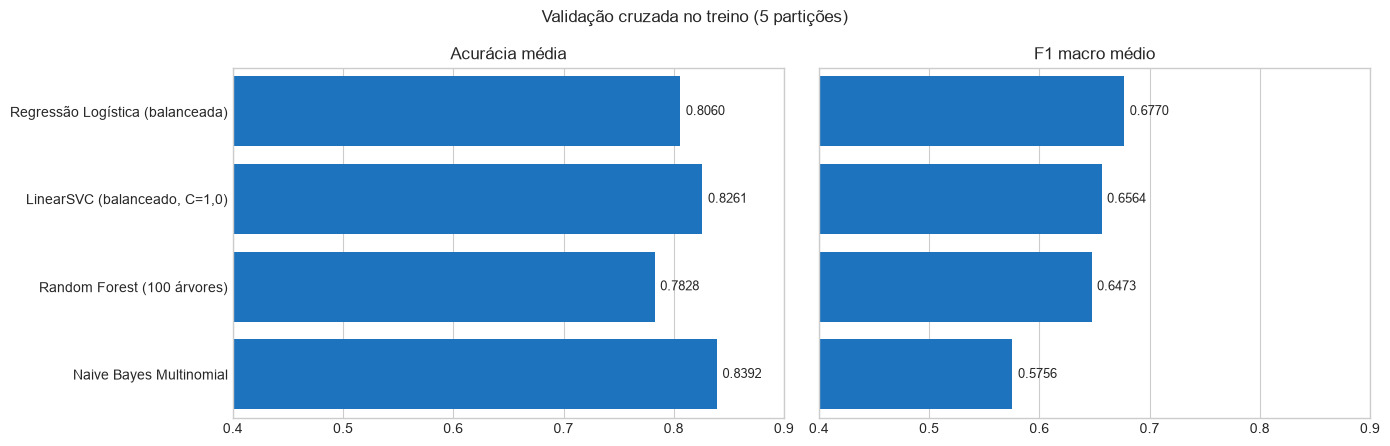

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, coluna, titulo in [
    (axes[0], "acuracia_media", "Acurácia média"),
    (axes[1], "f1_macro_medio", "F1 macro médio"),
]:
    sns.barplot(data=comparativo, x=coluna, y="modelo", color="#0275d8", ax=ax)
    ax.set_xlim(0.4, 0.9)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("")
    for barra in ax.patches:
        ax.annotate(f"{barra.get_width():.4f}", (barra.get_width() + 0.005, barra.get_y() + barra.get_height() / 2),
                    va="center", fontsize=9)
plt.suptitle("Validação cruzada no treino (5 partições)")
plt.tight_layout()
plt.show()

## 5. Leitura dos resultados

Os dois gráficos contam histórias diferentes, e é por isso que olhamos mais de uma métrica:

- O **Naive Bayes** tem a maior acurácia e o menor F1 macro. Essa combinação indica que ele acerta muito a classe positiva, que é a maior, e pouco as classes menores.
- A **Regressão Logística** tem o maior F1 macro, ou seja, o melhor equilíbrio entre as três classes, com acurácia um pouco menor.
- O **LinearSVC** fica perto da Regressão Logística no F1 ponderado e acima dela na acurácia, mas abaixo no F1 macro, porque reconhece menos neutros.
- A **Random Forest** tem a menor acurácia e o menor F1 ponderado; no F1 macro, só supera o Naive Bayes.

Os tempos são só indicativos: foram medidos uma vez, em uma máquina, e todos ficam na casa de segundos.

**Modelo oficial:** a Regressão Logística com pesos balanceados é o modelo implementado em `src/treinamento.py`, e o LinearSVC fica como referência de comparação. Nesta comparação, os pontos a favor dela são o maior F1 macro e o fato de gerar probabilidades estimadas, que podem servir a estudos de limiar desde que validadas. Nesta comparação os dois modelos usam `C=1,0`. A seção 6 ajusta o `C` de cada um para verificar se a diferença se mantém.

## 6. Ajuste do parâmetro C

O `C` controla a regularização: valores menores deixam o modelo mais simples, valores maiores deixam o modelo se ajustar mais ao treino. Aqui testamos alguns valores de `C` para os dois modelos lineares com `GridSearchCV`, usando 3 partições do treino e o F1 macro como critério, a mesma configuração do experimento descrito na Seção 8.2.2 do documento da Etapa 2. O conjunto de teste não entra nesta busca.

In [ ]:
buscas = {
    "Regressão Logística (balanceada)": (
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
        [0.1, 0.5, 1.0, 2.0, 5.0],
    ),
    "LinearSVC (balanceado)": (
        LinearSVC(class_weight="balanced", random_state=42, dual="auto"),
        [0.01, 0.1, 0.5, 1.0],
    ),
}
for nome, (classificador, valores_c) in buscas.items():
    pipeline = Pipeline([("tfidf", clone(vetorizador)), ("classificador", classificador)])
    busca = GridSearchCV(pipeline, {"classificador__C": valores_c}, cv=3, scoring="f1_macro", n_jobs=-1)
    busca.fit(df_treino["texto_limpo"], df_treino["sentimento"])
    notas = ", ".join(f"C={c}: {s:.4f}" for c, s in zip(valores_c, busca.cv_results_["mean_test_score"]))
    print(f"{nome}\n  F1 macro por C (3 partições): {notas}\n  Melhor C: {busca.best_params_['classificador__C']}\n")

Regressão Logística (balanceada)
  F1 macro por C (3 partições): C=0.1: 0.6649, C=0.5: 0.6775, C=1.0: 0.6750, C=2.0: 0.6721, C=5.0: 0.6650
  Melhor C: 0.5

LinearSVC (balanceado)
  F1 macro por C (3 partições): C=0.01: 0.6311, C=0.1: 0.6763, C=0.5: 0.6680, C=1.0: 0.6582
  Melhor C: 0.1



Leitura:

- Na **Regressão Logística**, o melhor valor foi `C=0,5`, mas o F1 macro fica praticamente igual ao do `C=1,0` usado no modelo oficial (0,6775 contra 0,6750). Por isso o modelo oficial mantém `C=1,0`.
- No **LinearSVC**, o melhor valor foi `C=0,1`, o mesmo relatado na Seção 8.2.2. Com esse ajuste ele sobe de 0,6582 para 0,6763 e fica empatado com a Regressão Logística no F1 macro.

Ajustado, o LinearSVC tem F1 negativo um pouco maior no teste (0,82 contra 0,81), mas perde na classe neutra e no F1 macro. Os dois atingem a Meta 1, e a Regressão Logística segue como modelo oficial por manter melhor equilíbrio entre as classes e gerar as probabilidades usadas no notebook 04. Os números no teste estão na Seção 8.3 do documento; este notebook usa só o treino.

## 7. Treino do modelo oficial

Chamamos `treinar_e_avaliar` de `src/treinamento.py`. A função treina o pipeline em todo o `treino.csv`, confere que nenhum texto limpo do teste aparece no treino e grava o modelo, as previsões no teste e as métricas. As métricas são analisadas no notebook 04, por isso não são exibidas aqui.

In [ ]:
dir_processado = BASE_DIR / "data" / "processed"
metricas = treinar_e_avaliar(
    dir_processado / "treino.csv",
    dir_processado / "teste.csv",
    dir_processado / "modelo",
)
for arquivo in ["modelo_sentimento.joblib", "metricas_modelo.json", "previsoes_teste.csv"]:
    print("Gravado:", f"data/processed/modelo/{arquivo}")

Gravado: data/processed/modelo/modelo_sentimento.joblib
Gravado: data/processed/modelo/metricas_modelo.json
Gravado: data/processed/modelo/previsoes_teste.csv


Próximo passo: notebook 04, que avalia esse modelo no conjunto de teste.